In [72]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import lu_factor, lu_solve

np.random.seed(42)

In [73]:

import matplotlib as mpl

# ---- STILE PAPER ----
mpl.rcParams.update({

    # Usa font LaTeX (coerente con paper)
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],

    # Dimensioni testo (standard journal)
    "font.size": 9,
    "axes.titlesize": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,

    # Spessori ottimizzati per stampa
    "lines.linewidth": 1.2,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,

    # Tick dentro (stile PRL/JCP)
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Griglia molto leggera
    "grid.linestyle": ":",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,

    # Legenda minimale
    "legend.frameon": False,
})

In [74]:
def generate_random_f_from_white_noise(t_array: np.ndarray,sigma_white_noise: float = 1, sigma_filter: float = 1, T_0: float = 0, oscillations_power: float = 1, verbose:bool=False) -> np.ndarray:
    
    nt = t_array.size
    if nt == 1:
        raise ValueError('nt must be greater than 1')

    dt = t_array[1]-t_array[0]

    max_freq = 1/dt
    min_freq = 1/(t_array[-1]-t_array[1])
    
    if verbose:
        print("Max freq: ", max_freq)
        print("Min freq: ", min_freq)
        
    # NOTE: la sigma del filtro va scelta tenendo conto dello spetto consentito dalla discretizzazione temporale 
    # Io ho trovato che un sigma circa 3-5 volte la frequenza minima produce delle funzione che APPARENTEMENTE sembrano buone,
    # la validità di questa affermazione andrà testata
    if(sigma_filter < min_freq):
        print("Attenzione: sigma_filter minore della frequenza minima consentita.")

    # Genera white noise nel tempo
    # Proprietà da rispettare:
    # - Media nulla
    # - Matrice di correlazione proporzionale all'identità
    f = np.random.normal(0,sigma_white_noise,nt)

    f_hat = np.fft.rfft(f)
    freqs = np.fft.rfftfreq(nt, dt)

    # Applica filtro gaussiano nello spazio delle frequenze
    # NOTE: Il filtro gaussiano è una scelta di comodo, bisogna capire in base al problema
    # che tipo di filtro nello spazio delle frequenza applicare. Questo mi aspetto influenzi fortemente la fase 
    # di training e la risultante capacità di generalizzazione del modello.
    filter = np.exp(-(freqs**2)/(2*sigma_filter**2))

    f_hat_filtered = f_hat * filter

    f_filtered = np.fft.irfft(f_hat_filtered, n=nt)

    # Normalizza f_filtered e rendilo fisicamente coerente con una possibile oscillazione attorno a un valore noto.
    # Di default oscilla attorno a 0 con amplificazione unitaria.
    f_filtered = (f_filtered - f_filtered.mean()) / f_filtered.std()
    f_filtered = T_0 + oscillations_power*f_filtered
    
    # Plot del white noise e della funzione generata
    if verbose:
        plt.figure(figsize=(6.8, 4.4))   
        plt.plot(t_array, f, label="White noise", alpha=0.5)
        plt.plot(t_array, f_filtered, label="f_filtered", lw=2)
        plt.legend()
        plt.xlabel("Time")
        plt.ylabel("Temperature")
        plt.title("White noise e f risultante")
        plt.show()

    return f_filtered


# Test generazione dataset di funzioni

Genero un dataset di funzioni usando "generate_random_f_from_white_noise". In seguito tratto le funzioni generate come vettori e calcolo la matrice di correlazione.

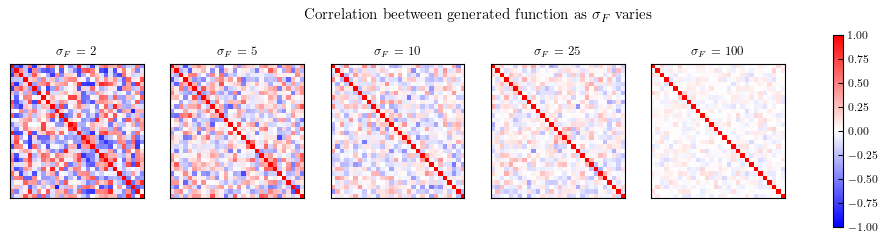

In [ ]:
f_dataset_size = 30
nt = 1000
t_array = np.linspace(0,1,nt)

f_dataset = np.zeros(shape=(nt,f_dataset_size))

dt = t_array[1]-t_array[0]   

fig, axes = plt.subplots(1,5,figsize=(12.5,2.5))   
index_ax = 0

for sigma_filter in [2,5,10,25,100]:
    
    for index in range(f_dataset_size):
        f_dataset[:,index] = generate_random_f_from_white_noise(t_array, sigma_filter=sigma_filter)

    # Verifico l'indipendenza tra le funzioni generate
    f_corr = np.corrcoef(f_dataset, rowvar=False)

    im = axes[index_ax].imshow(f_corr, cmap='bwr', vmin=-1, vmax=1)
    axes[index_ax].set_title(rf"$\sigma_F$ = {sigma_filter}")
    axes[index_ax].set_xticks([])
    axes[index_ax].set_yticks([])
    index_ax=index_ax+1

fig.colorbar(im, ax=axes.ravel().tolist())
fig.suptitle(r"Correlation beetween generated function as $\sigma_F$ varies")

plt.savefig("assets/dataset_function_correlations.pdf")
plt.show()

Il filtro passa basso nello spazio di fourier assieme alla continuità delle funzioni introduce una correlazione nel dataset. Il filtro proietta le funzioni su un sottospazio di dimensione sempre più piccola al diminuire della sigma_filtro. Questo si vede dalla diminuzione della correlazione con l'aumento della sigma del filtro gaussiano.

dx:  0.0020408163265306124
dt:  0.03
Errore spaziale:  4.164931278633903e-06
Errore temporale: 0.0009
Time scale caratteristica:  100.00000000000001
r:  0.7202999999999999
Max freq:  33.33
Min freq:  0.0033336667333466693


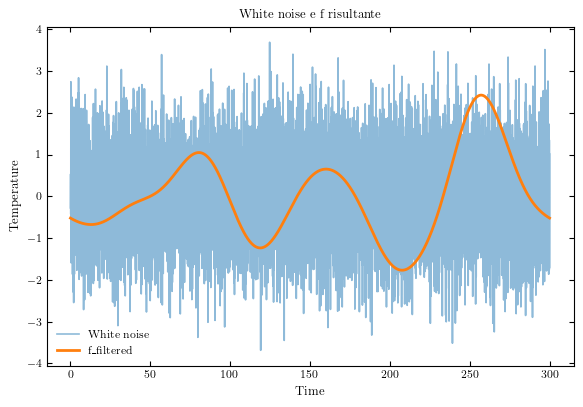

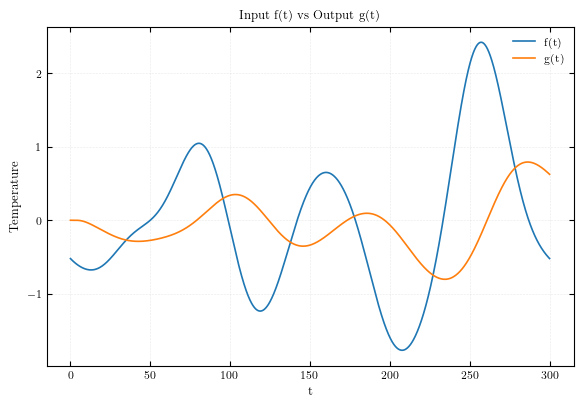

In [81]:
L = 0.1         # Lunghezza totale
Tf = 300        # Tempo finale
nx = 50         # Griglia spaziale
nt = 10000      # Griglia temporale

dx = L/(nx-1)
dt = Tf/nt

print("dx: ", dx)
print("dt: ", dt)

print("Errore spaziale: ", dx**2)
print("Errore temporale:", dt**2)

D = 0.0001
r = D*dt/(dx**2)

h = 1

print("Time scale caratteristica: ", L*L/D)
print("r: ", r)

if(r > 1):
    print("ATTENZIONE: per garantire stabilità numerica e risultati fisicamente corretti è consigliabile avere r minore o uguale a 1.")

x_array = np.linspace(0, L, nx)
t_array = np.linspace(0,Tf,nt)

# Matrici A e B
A = np.zeros((nx, nx))
B = np.zeros((nx, nx))

# Nodi interni
for i in range(1, nx-1):

    A[i, i-1] = -r/2
    A[i, i]   = (1 + r)
    A[i, i+1] = -r/2

    B[i, i-1] = r/2
    B[i, i]   = (1 - r)
    B[i, i+1] = r/2

# Boundary sinistra (Dirichlet)
A[0,0] = 1
B[0,:] = 0

# Boundary destra (Robin)
A[-1, -3] = 1
A[-1, -2] = -4
A[-1, -1] = 3 + 2*h*dx
B[-1, :] = 0 

lu, piv = lu_factor(A)

T = np.zeros(shape=(nx,nt))

# ----------------------------------------------------------
# NOTE: Sezione da inserire nel loop per la generazione del dataset
# Tutto ciò che precede questa sezione è indipendente dalla simulazione
# sotto la condizione di tenere fissi i parametri di D, h e la discretizzazione spazio-temporale

T[:,0] = 0 # Initial condition

f = generate_random_f_from_white_noise(t_array, sigma_filter=0.01, verbose=True)
T[0,0] = f[0]

# Questo loop risolve step by step l'equazione implicità
# A*T(n+1) = B*T(n) + b(n+1)
for n in range(1,nt):
    b = B @ T[:,n-1]
    b[0] = f[n] # impongo dirichlet
    T[:,n] = lu_solve((lu, piv), b)

# ----------------------------------------------------------

plt.figure(figsize=(6.8, 4.4))  
plt.plot(t_array, T[0,:], label="f(t)")
plt.plot(t_array, T[-1,:], label="g(t)")
plt.legend()
plt.grid()
plt.xlabel("t")
plt.ylabel("Temperature")
plt.title("Input f(t) vs Output g(t)")
plt.show()